In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import EFC_learningfMRI.globals as gl
import EFC_learningfMRI.ofc_chords as ofc
import EFC_learningfMRI.behaviour as behav

base directory found: /Volumes/diedrichsen_data$/data/Chord_exp/EFC_learningfMRI
Atlas directory found: atlases
figure directory found: figures/


# Chords
The model is trained on the same chords used with the participants.

In [2]:
chords        = ofc.make_chords()
patterns_dict = ofc.chords_to_targets(chords, flex_force=3.0, ext_force=3.0)

patterns_dict

{np.int64(11911): array([3., 3., 0., 3., 3.]),
 np.int64(12129): array([ 3., -3.,  3., -3.,  0.]),
 np.int64(12291): array([ 3., -3., -3.,  0.,  3.]),
 np.int64(21291): array([-3.,  3., -3.,  0.,  3.]),
 np.int64(21911): array([-3.,  3.,  0.,  3.,  3.]),
 np.int64(22911): array([-3., -3.,  0.,  3.,  3.]),
 np.int64(91211): array([ 0.,  3., -3.,  3.,  3.]),
 np.int64(92122): array([ 0., -3.,  3., -3., -3.])}

# Enslaving matrix
A single enslaving matrix for flexion and extension: motor commands are signed (negative = flexion, positive = extension, as the target forces). The matrix is n [fingers] x m [motor commands]. Each column represents how the corresponding command spreads across fingers.

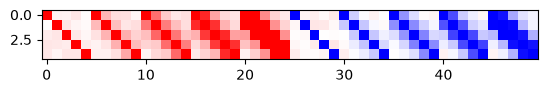

In [34]:
n = 5 # n_fingers
spread = np.linspace(0, 1, 5)  # spread of the enslaving matrix

E = []

# flexion commands
for u in range(5):
    E0 = ofc.make_enslaving(spread=spread[u])   
    e = .1 * np.random.rand(n,n)
    np.fill_diagonal(e, 0)
    E.append(E0 + e)

# extension commands
for u in range(5):
    E0 = -1 * ofc.make_enslaving(spread=spread[u]) 
    e = .1 * np.random.rand(n,n)
    np.fill_diagonal(e, 0)
    E.append(E0 + e)

E = np.hstack(E)

plt.imshow(E, cmap='bwr', vmin=-1, vmax=1)

# Plant
The forces of the n=5 fingers, driven by m=50 motor commands that spread across fingers through the enslaving matrices. Sensory delay is 0.1 s and the time constant of the plant is 0.03 s.

In [35]:
rng = np.random.default_rng(seed=0)

delay = int(.1 * gl.fsample['force'])  # sensory delay in samples (100 ms)
tau   = .04  # time constant of the plant (40 ms)

# init plant
plant = ofc.Plant(E=E, delay=delay, dt = 1 / gl.fsample['force'], tau=tau, motor_sdn=0.08)

# Internal model
The model learns is the enslaving matrix between fingers, i.e., how the plant reacts to the motor commands. The initial guess is that each motor commands only moves a single finger.

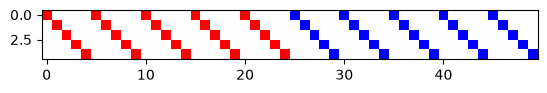

In [22]:
# naive guess: each command moves only its own finger, in its own direction.
# Column j of E belongs to finger j % n, so keep only that entry (+1 or -1)
# and set all enslaving (the other fingers) to 0.
m = E.shape[1]
cols = np.arange(m)
E_guess = np.zeros_like(E)
E_guess[cols % n, cols] = E[cols % n, cols]

internal_model = ofc.initial_model(plant, enslaving_guess=E_guess)

plt.imshow(E_guess, cmap='bwr', vmin=-1, vmax=1)

# Controller

In [60]:
k = plant.m // plant.n                       # motor commands per finger
b = plant.gain                               # dt / tau: effect of one step of command on force

Q = np.eye(plant.n)                          # error cost: one weight per finger
# r = .5 + np.random.rand(plant.m)              # effort cost: one weight per command, at the balance point
R = k * b ** 2 * r * np.eye(plant.m)             # effort cost: one weight per command, at the balance point

chordID = gl.chordID[1]
pattern = patterns_dict[chordID]

controller = ofc.design_controller(internal_model, plant, pattern, Q, R)

# Simulate trial

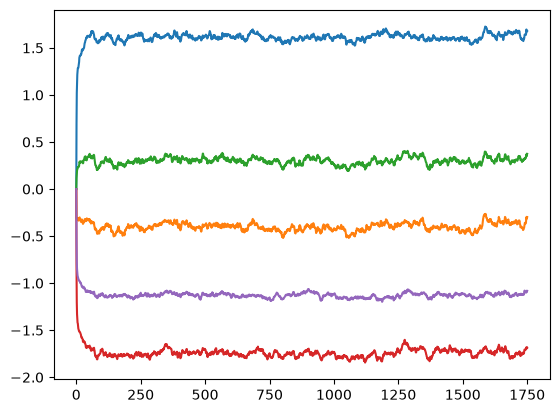

In [59]:
rng     = np.random.default_rng(seed=1)
n_steps = int(3.5 * gl.fsample['force'])
trial   = ofc.simulate_trial(plant, controller, n_steps=n_steps, rng=rng)

plt.plot(trial['x'])